# 下載 MNIST 資料
---
首先，匯入 keras 和相關模組。

In [71]:
# 匯入 numpy 和 pandas 模組，numpy 是 python 的程式庫，支援維度陣列與矩陣運算。
# pandas 則提供檔案存取和數據操縱。
import numpy as np
import pandas as pd
# 從 keras.utils 匯入 to_categroical，因為後續要將 label 標籤 轉換成 one-hot encoding。
from tensorflow.keras.utils import to_categorical
# 設定 seed 可以讓每次產生隨機值時，都會有相同的輸出。(若使用GPU，則無法每次皆相同)
seed = 1234
np.random.seed(seed)

Keras 中已經提供許多機器學習常用的數據集，包括波士頓房地產數據、CIFAR10、和這次範例要使用的手寫數據集。所以先從 keras 匯入 MNIST。

第一次執行 mnist.load_data() ，程式會檢查目錄是否已經有檔案，如果沒有就會自動下載，所以第一次可能都會比較久。之後再次執行時不用再次下載就會快速很多。


In [72]:
from tensorflow.keras.datasets import mnist,cifar10
(X_train_image, y_train_label),\
    (X_test_image, y_test_label) = mnist.load_data()

先來看看 MNIST 資料數據集的筆數，還有訓練資料的組成。

可以看到 train 訓練資料有 60000 筆，test 測試資料有 10000 筆。

訓練資料是由 images 和 labels 所組成共 60000 筆， images 是單色的數字影像，labels 是數字影像對應的真實值。

In [73]:
print('train data : ', len(X_train_image))
print('test data : ', len(X_test_image))

train data :  60000
test data :  10000


In [74]:
print('x_train_image : ', X_train_image.shape)
print('y_train_label : ', y_train_label.shape)

x_train_image :  (60000, 28, 28)
y_train_label :  (60000,)


# 建立 plot_image 函式來顯示數字影像
---
來看看剛剛匯入的手寫數字圖像。



In [75]:
import matplotlib.pyplot as plt
def plot_image(image):
    # 設定圖形顯示大小
    fig = plt.gcf()
    fig.set_size_inches(2, 2)
    # 使用 plt.imshow() 顯示圖像，傳入參數是 28 X 28 的圖形，
    # cmap 參數設定為 binary 以黑白灰階顯示
    plt.imshow(image, cmap = 'binary')
    # 開始繪圖
    plt.show()

傳入訓練集第一筆資料，來看看他的影像。

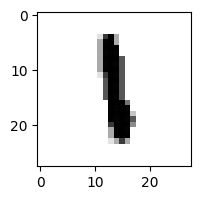

In [76]:
plot_image(X_train_image[200])

看看第一筆資料的 label

In [77]:
y_train_label[200]

np.uint8(1)

# 查看多筆資料 images 與 labels
---
定義 plot_images_labels_prediction() 函式，傳入以下參數：images(數字影像)、labels(對應數字真實值)、prediction(預測結果)、idx(開始顯示影像的index)、num(要顯示的資料筆數，預設是10，不超過25)


In [78]:
def plot_images_labels_prediction(images, labels, prediction,
                                    idx, num = 10):
    # 設定顯示圖形大小
    fig = plt.gcf()
    fig.set_size_inches(12, 14)
    # 如果顯示筆數大於25 則將他設定為25 以避免錯誤
    if num > 25: num = 25
    # 使用 for 迴圈依序畫出 num 個數字圖形
    for i in range(0, num):
        ax = plt.subplot(5, 5, 1+i) # 建立 5 X 5 的 subgraph 子圖形
        ax.imshow(images[idx], cmap = 'binary') # 畫出 subgraph 子圖形
        title = "label=" + str(labels[idx]) # 設定子圖形 title 顯示標籤欄位
        if len(prediction) > 0: # 如果 prediction 有傳入值
            title += ",predict=" + str(prediction[idx]) # 將 prediction 加入 title
        ax.set_title(title, fontsize = 10) # 設定標題大小
        ax.set_xticks([]); ax.set_yticks([]) # 設定不顯示刻度
        idx += 1 # 讀取下一筆
    plt.show() # 開始畫圖

顯示訓練資料前 10 筆資料。不過目前還沒有預測結果所以傳入空 list ，由第 0 筆開始顯示至第 9 筆。

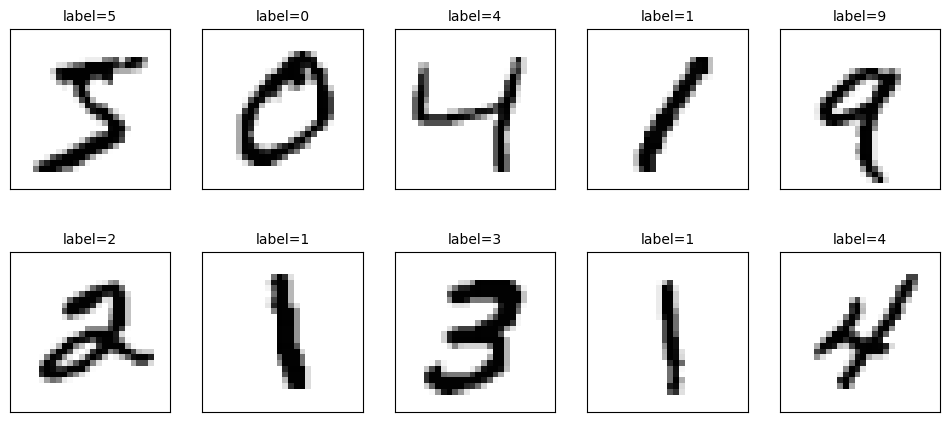

In [79]:
plot_images_labels_prediction(X_train_image, y_train_label, [], 0, 10)

查看 test 測試資料筆數，可以看到共10000筆資料。

In [80]:
print('x_test_image : ', X_test_image.shape)
print('y_test_label : ', y_test_label.shape)

x_test_image :  (10000, 28, 28)
y_test_label :  (10000,)


顯示測試資料前 10 筆資料圖形。

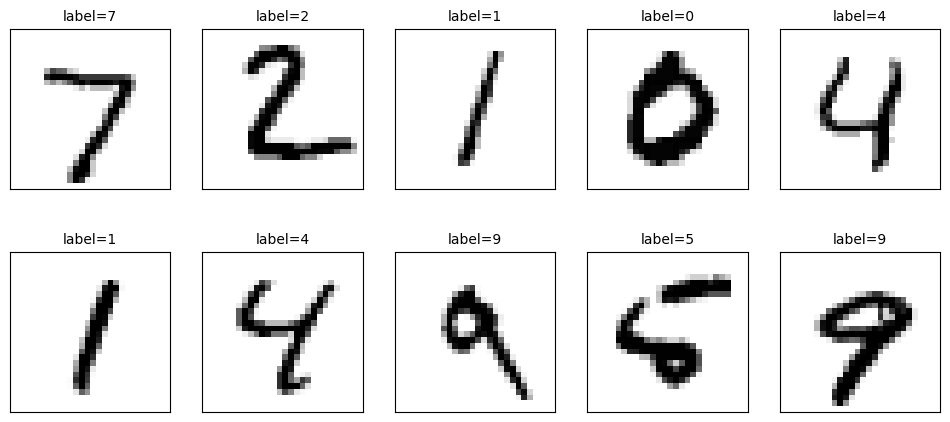

In [81]:
plot_images_labels_prediction(X_test_image, y_test_label, [], 0, 10)

# feature(數字影像的特徵值)資料預處理


In [82]:
X_Train = X_train_image.astype('float32')
X_Test = X_test_image.astype('float32')

將影像資料型態轉換為 float32，後續將在模型中攤平為 784 個特徵值。

In [83]:
print('x_train : ', X_Train.shape)
print('x_test : ', X_Test.shape)

x_train :  (60000, 28, 28)
x_test :  (10000, 28, 28)


將 image 的數字標準化。

因為圖像的數字是介於 0 到 255，所以最簡單的方法就是除以 255。

In [84]:
X_Train_normalize = X_Train / 255
X_Test_normalize = X_Test / 255

# labels(數字影像對應真實值)資料預處理
---
先來查看一下訓練資料 label 標籤欄位前五筆資料，可以看到這是 0 ~ 9 的單一數字。

In [85]:
y_train_label[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

使用我們開頭匯入的 to_categorical函式，傳入 label 標籤，將他們轉換成 one-hot encoding。

In [86]:
y_TrainOneHot = to_categorical(y_train_label)
y_TestOneHot = to_categorical(y_test_label)

查看轉換過後的結果。

In [87]:
y_TrainOneHot[:5]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

# 建立 MLP 模型
---
接下來建立多層感知器模型，將 28 × 28 的影像攤平成 784 個特徵，經過 256、128 個神經元的兩個隱藏層，最後輸出 0～9 共 10 類的預測結果。

原始範例的隱藏層為 32 個神經元，這裡改成兩層，並使用 ReLU 和 Dropout(0.2)。

首先匯入所需要的模組。

In [88]:
from tensorflow.keras import layers, metrics
from tensorflow.keras.layers import Dense,InputLayer,Flatten
from tensorflow.keras import models
import tensorflow as tf
tf.random.set_seed(seed)

建立 Sequential 一個線性堆疊模型，後續只要使用 model.add() 將個神經網路層依序加入模型即可。

In [89]:
# 清除上一個模型，並固定亂數種子，從頭建立模型。
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(seed)
model = models.Sequential(name='Lab8_MLP_256_128')

建立輸入層
1.   設定輸入層神經元 維度為 (28,28,1)。
2.   把(28,28,1)攤平，變成一維

In [90]:
# 灰階影像維持 (28,28,1)，與樹莓派預測程式相容。
X_Train_normalize = X_Train_normalize.reshape(-1, 28, 28, 1)
X_Test_normalize = X_Test_normalize.reshape(-1, 28, 28, 1)
model.add(layers.Input(shape=(28, 28, 1)))
# MLP 先將影像攤平成 784 個特徵。
model.add(layers.Flatten())

建立隱藏層。
1. 將原本 32 個神經元的隱藏層改成兩層，分別為 256、128 個神經元。
2. 將原本的 sigmoid 改為 ReLU。
3. 每個隱藏層後加入 Dropout(0.2)，訓練時隨機停用 20% 輸出，預測時不啟用。

可以在 keras 官方文件查看可以使用的 Activation function。
https://keras.io/zh/activations/

In [91]:
# 將原本 32 個神經元的隱藏層改成 256、128 兩層，激活函數改為 ReLU。
# 每層後加入 Dropout(0.2)，訓練時隨機停用 20% 輸出，減少過度擬合。
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.2))
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dropout(0.2))

建立輸出層總共 10 個神經元，對應要分類的數字類別 0 ~ 9 。設定激活函數為 softmax ，這樣每一個神經元的輸出結果可視為預測每一個數字的機率。

In [92]:
model.add(Dense(10, kernel_initializer = 'normal', activation = 'softmax'))

來看看我們建好的模型的摘要。

In [93]:
print(model.summary())

Model: "Lab8_MLP_256_128"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

None


# 進行訓練
---
首先使用 compile，對訓練模型進行設定。相關參數有：
1. loss：設定損失函數，這裡保留 CategoricalCrossentropy，搭配 one-hot 標籤。
2. optimizer：將原本的 SGD 改成 Adam。keras 也提供其他優化方法：https://keras.io/zh/optimizers/
3. metrics：使用 accuracy 評估分類準確率。

In [94]:
# 將優化器由 SGD 改為 Adam，損失函數維持不變。
loss_function = 'CategoricalCrossentropy'
optimize_function = 'adam'
model.compile(loss=loss_function, optimizer=optimize_function, metrics=['accuracy'])

開始訓練，過程會儲存在 train_history 變數。
1. validation_split = 0.2：原訓練資料的 80% 用來訓練，20% 用來驗證。
2. epochs = 20：最多訓練 20 輪，EarlyStopping 可能提前停止。每批 batch_size 為 200 筆。
3. ReduceLROnPlateau：驗證 loss 連續 2 輪未改善時，將學習率減半，最低為 0.00001。
4. EarlyStopping：驗證 loss 連續 5 輪未改善就停止，並恢復驗證 loss 最低時的權重。
5. verbose = 2：顯示每輪訓練結果。

兩個 callback 都監控驗證資料，測試資料只在訓練完成後用來評估。

In [95]:
# 驗證 loss 連續 2 輪沒有下降時，將學習率減半。
# 連續 5 輪沒有下降就停止訓練，並恢復驗證 loss 最低時的權重。
# 最多訓練 20 輪，每批 200 筆，保留 20% 資料作為驗證。
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
]
train_history = model.fit(
    x=X_Train_normalize, y=y_TrainOneHot,
    validation_split=0.2, epochs=20, batch_size=200,
    callbacks=callbacks, verbose=2
)
best_epoch = int(np.argmin(train_history.history['val_loss'])) + 1
print(f'實際訓練 {len(train_history.history["loss"])} 輪；採用第 {best_epoch} 輪權重')
print('最佳 val_loss:', min(train_history.history['val_loss']))

Epoch 1/20
240/240 - 4s - 17ms/step - accuracy: 0.8582 - loss: 0.4913 - val_accuracy: 0.9466 - val_loss: 0.1857 - learning_rate: 0.0010
Epoch 2/20
240/240 - 3s - 14ms/step - accuracy: 0.9418 - loss: 0.1924 - val_accuracy: 0.9614 - val_loss: 0.1328 - learning_rate: 0.0010
Epoch 3/20
240/240 - 6s - 26ms/step - accuracy: 0.9592 - loss: 0.1364 - val_accuracy: 0.9672 - val_loss: 0.1078 - learning_rate: 0.0010
Epoch 4/20
240/240 - 3s - 11ms/step - accuracy: 0.9675 - loss: 0.1069 - val_accuracy: 0.9722 - val_loss: 0.0931 - learning_rate: 0.0010
Epoch 5/20
240/240 - 3s - 11ms/step - accuracy: 0.9731 - loss: 0.0876 - val_accuracy: 0.9746 - val_loss: 0.0869 - learning_rate: 0.0010
Epoch 6/20
240/240 - 3s - 11ms/step - accuracy: 0.9770 - loss: 0.0735 - val_accuracy: 0.9760 - val_loss: 0.0805 - learning_rate: 0.0010
Epoch 7/20
240/240 - 3s - 14ms/step - accuracy: 0.9792 - loss: 0.0655 - val_accuracy: 0.9755 - val_loss: 0.0784 - learning_rate: 0.0010
Epoch 8/20
240/240 - 4s - 15ms/step - accuracy: 

建立函式顯示訓練過程，會將每一個訓練週期的 accuracy 和 loss 以圖表顯示出來。

In [96]:
def show_train_history(train_history, train, validation):
    plt.plot(train_history.history[train])
    plt.plot(train_history.history[validation])
    plt.title('Train History')
    plt.ylabel(train)
    plt.xlabel('Epoch')
    plt.legend(['train', 'validation'], loc = 'upper left')
    plt.show()

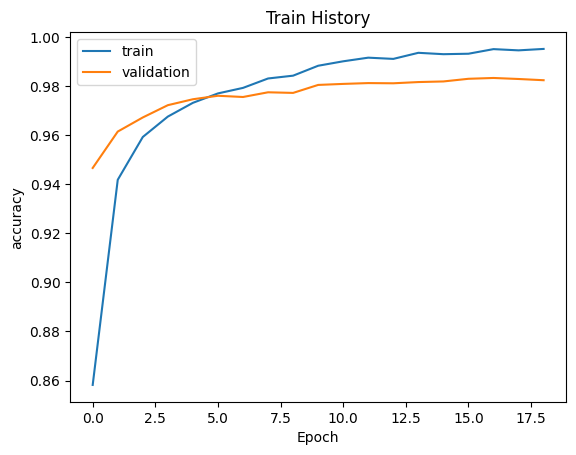

In [97]:
show_train_history(train_history, 'accuracy', 'val_accuracy')

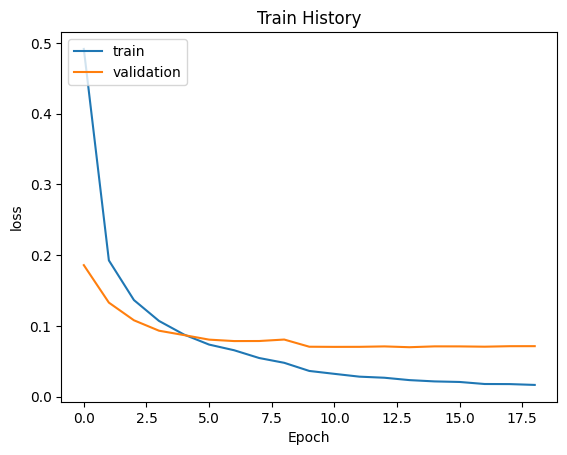

In [98]:
show_train_history(train_history, 'loss', 'val_loss')

# 以測試資料評估模型準確率
---


In [99]:
scores = model.evaluate(X_Test_normalize, y_TestOneHot)
print()
print('accuracy = ', scores[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9830 - loss: 0.0590

accuracy =  0.9829999804496765


執行預測，將結果存到 prediction 中。

In [100]:
prediction = np.argmax(model.predict(X_Test_normalize), axis = -1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [101]:
prediction

array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

顯示 10 筆預測結果。

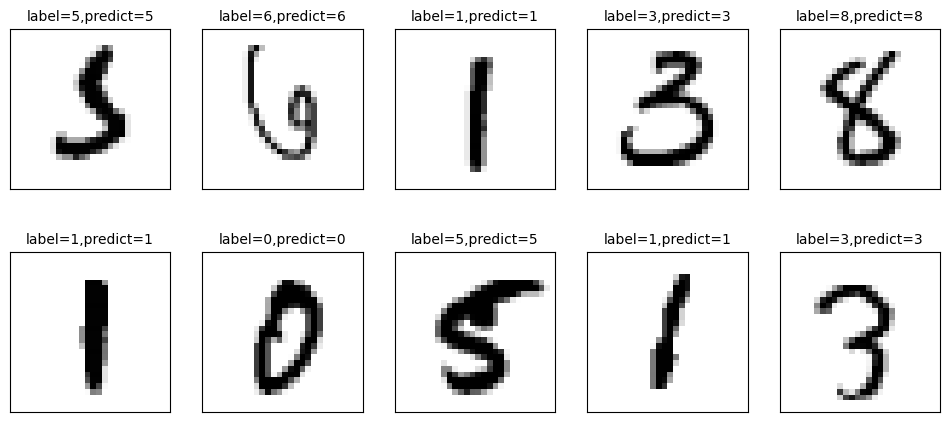

In [102]:
plot_images_labels_prediction(X_test_image, y_test_label, prediction, idx = 340)

In [103]:
y_test_label = y_test_label.reshape(10000)

混淆矩陣

In [104]:
#使用 pandas 中的 crosstab 能夠很方便的建立混淆矩陣。
pd.crosstab(y_test_label, prediction, rownames = ['label'], colnames = ['predict'])

predict,0,1,2,3,4,5,6,7,8,9
label,,,,,,,,,,
0,971,0,0,1,0,0,4,1,3,0
1,0,1126,2,0,0,1,2,0,4,0
2,5,0,1013,0,1,0,2,7,4,0
3,0,0,1,994,0,6,0,4,3,2
4,1,0,2,0,961,0,3,3,1,11
5,2,0,0,6,1,874,4,0,4,1
6,5,2,0,1,5,3,941,0,1,0
7,1,3,5,3,0,0,0,1008,3,5
8,1,0,5,3,1,1,1,4,957,1


In [105]:
import tensorflow as tf
from datetime import datetime
from zoneinfo import ZoneInfo
from google.colab import files

# 修改：以台灣時間加入日期、時間及微秒，區分每次匯出的模型。
timestamp = datetime.now(ZoneInfo('Asia/Taipei')).strftime('%Y%m%d_%H%M%S_%f')
filename = f'mnist_model_{timestamp}.tflite'

# 將目前訓練完成的模型轉換為 TFLite。
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# 使用 xb 建立新檔；若同名檔案已存在則報錯，避免覆蓋。
with open(filename, 'xb') as f:
    f.write(tflite_model)

print(f'模型已儲存：{filename}')
files.download(filename)

Saved artifact at '/tmp/tmpqcmedxzj'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  135352422907152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135352422905040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135352422902544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135352422901008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135352422903504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135352390355280: TensorSpec(shape=(), dtype=tf.resource, name=None)
模型已儲存：mnist_model_20261124_033202_290333.tflite


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>